# Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

**Objective**: delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

**Dataset**: [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)

## Setup

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

df = pd.read_csv("data/amz_uk_price_prediction_dataset.csv")
df.shape

(2443651, 9)

---
## Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: understand the relationship between product categories and their best-seller status.

### 1. Crosstab Analysis
- Create a crosstab between the product `category` and the `isBestSeller` status.
- Are there categories where being a best-seller is more prevalent?

*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*

In [27]:
# Crosstab with absolute counts: rows = categories, columns = best-seller status (False / True)
crosstab = pd.crosstab(df["category"], df["isBestSeller"])
crosstab.head()

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3


In [28]:
# Proportion of best-sellers inside each category (each row sums to 1), sorted from the highest
bestseller_prop = pd.crosstab(df["category"], df["isBestSeller"], normalize="index")[True]

# Put counts and proportion together so we can also see how many listings each category has
bestseller_table = crosstab.copy()
bestseller_table["total"] = crosstab.sum(axis=1)
bestseller_table["bestseller_pct"] = (bestseller_prop * 100).round(2)
bestseller_table = bestseller_table.sort_values("bestseller_pct", ascending=False)

print(f"Overall share of best-sellers: {df['isBestSeller'].mean() * 100:.2f}%")
print(f"Categories with no best-seller at all: {(crosstab[True] == 0).sum()} out of {len(crosstab)}")
bestseller_table.head(10)

Overall share of best-sellers: 0.33%
Categories with no best-seller at all: 36 out of 296


isBestSeller,False,True,total,bestseller_pct
category,,,,
Grocery,9008,556,9564,5.81
Smart Home Security & Lighting,98,6,104,5.77
Health & Personal Care,9017,552,9569,5.77
Mobile Phone Accessories,248,11,259,4.25
Power & Hand Tools,8353,306,8659,3.53
"Billiard, Snooker & Pool",241,8,249,3.21
Pet Supplies,9152,285,9437,3.02
Home Brewing & Wine Making,239,7,246,2.85
Wind Instruments,243,7,250,2.80


### 2. Statistical Tests
- Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
- Compute Cramér's V to understand the strength of association between best-seller status and category.

In [29]:
# Chi-square test of independence on the crosstab
# H0: being a best-seller is independent of the category
chi2, p_value, dof, expected = stats.chi2_contingency(crosstab)
print(f"Chi-square: {chi2:,.2f}")
print(f"p-value:    {p_value}")
print(f"Degrees of freedom: {dof}")

# The test is reliable only if the expected counts are not too small (rule of thumb: >= 5)
print(f"Cells with expected count < 5: {(expected < 5).mean() * 100:.1f}%")

Chi-square: 36,540.20
p-value:    0.0
Degrees of freedom: 295
Cells with expected count < 5: 19.3%


In [30]:
# Cramér's V = sqrt(chi2 / (n * (min(rows, columns) - 1))): 0 = no association, 1 = perfect association
n = crosstab.to_numpy().sum()
min_dim = min(crosstab.shape) - 1
cramers_v = np.sqrt(chi2 / (n * min_dim))
print(f"Cramér's V: {cramers_v:.3f}")

Cramér's V: 0.122


### 3. Visualizations
- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

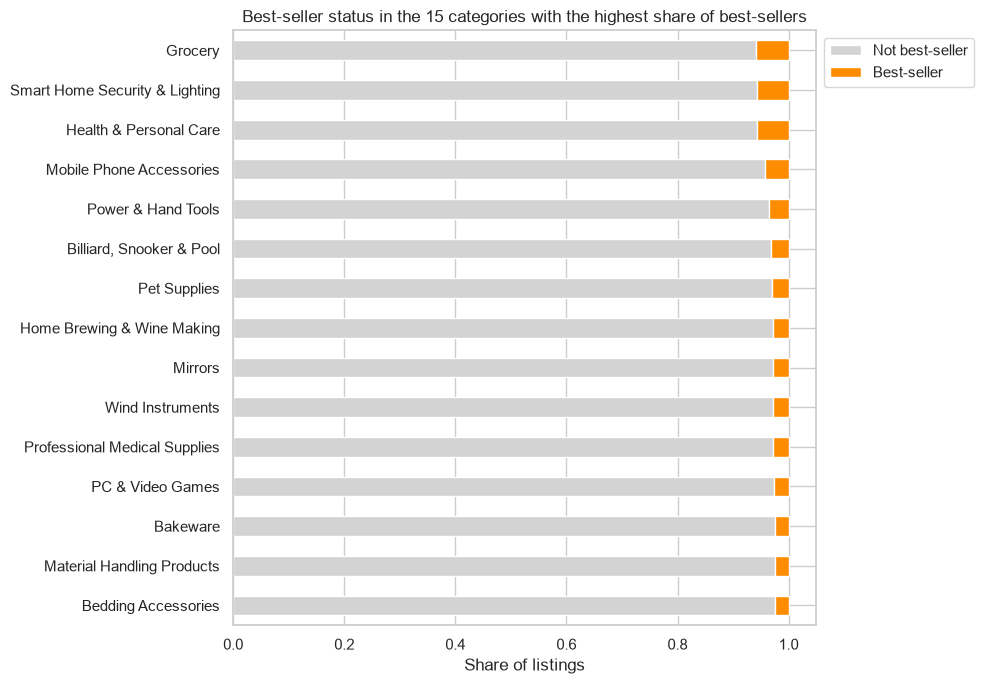

In [31]:
# 296 categories are too many for a readable chart: we plot the 15 with the highest share of best-sellers
prop_table = pd.crosstab(df["category"], df["isBestSeller"], normalize="index")
prop_table = prop_table.rename(columns={False: "Not best-seller", True: "Best-seller"})
top_prop = prop_table.sort_values("Best-seller", ascending=False).head(15)

# Horizontal stacked bars: each bar is 100% of the listings of a category
ax = top_prop.sort_values("Best-seller").plot(kind="barh", stacked=True, figsize=(10, 7),
                                              color=["lightgrey", "darkorange"])
ax.set_title("Best-seller status in the 15 categories with the highest share of best-sellers")
ax.set_xlabel("Share of listings")
ax.set_ylabel("")
ax.legend(title="", loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

### Part 1 - Findings
- **Best-sellers are rare**: only 0.33% of the listings are best-sellers, and 36 of the 296 categories have none.
- **Where they are more prevalent**: *Grocery* (5.81% of its listings), *Smart Home Security & Lighting* (5.77%, but only 104 listings) and *Health & Personal Care* (5.77%). The largest category, *Sports & Outdoors*, has almost none (0.04%).
- **Chi-square test**: chi2 = 36,540 with 295 degrees of freedom and p-value ~ 0, so we reject independence: best-seller status depends on the category. About 19% of the expected counts are below 5, which is close to the usual limit but still acceptable.
- **Cramér's V = 0.12**: the association is weak. With 2.4 million rows the test detects any dependence, so the strength matters more than the p-value: category explains only a small part of who becomes a best-seller.
- **Caution**: small categories can reach high percentages with just a few best-sellers.


---
## Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: investigate how different product categories influence product prices.

### 0. Preliminary Step: Remove outliers in product prices
Use the IQR method: products priced below Q1 - 1.5 * IQR or above Q3 + 1.5 * IQR are considered outliers and removed. The next steps are done with the dataframe without outliers.

In [32]:
# IQR method on the price column
q1 = df["price"].quantile(0.25)
q3 = df["price"].quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
print(f"Q1 = £{q1:.2f}, Q3 = £{q3:.2f}, IQR = £{iqr:.2f}")
print(f"Fences: £{lower_fence:.2f} / £{upper_fence:.2f}")

# Keep only the prices inside the fences
df_clean = df[(df["price"] >= lower_fence) & (df["price"] <= upper_fence)].copy()
print(f"Rows removed: {len(df) - len(df_clean):,} ({(len(df) - len(df_clean)) / len(df) * 100:.1f}%)")
print(f"Rows kept:    {len(df_clean):,}")

Q1 = £9.99, Q3 = £45.99, IQR = £36.00
Fences: £-44.01 / £99.99


Rows removed: 327,688 (13.4%)
Rows kept:    2,115,963


In [33]:
# Products with stars = 0 have no rating yet: for every analysis on ratings we use only the rated products
df_rated = df_clean[df_clean["stars"] > 0].copy()
print(f"Products without rating (stars = 0) in df_clean: {(df_clean['stars'] == 0).mean() * 100:.1f}%")
print(f"Rated products: {len(df_rated):,}")

Products without rating (stars = 0) in df_clean: 47.3%
Rated products: 1,114,343


### 1. Violin Plots
- Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
- Which product category tends to have the highest median price? Don't filter here by top categories.

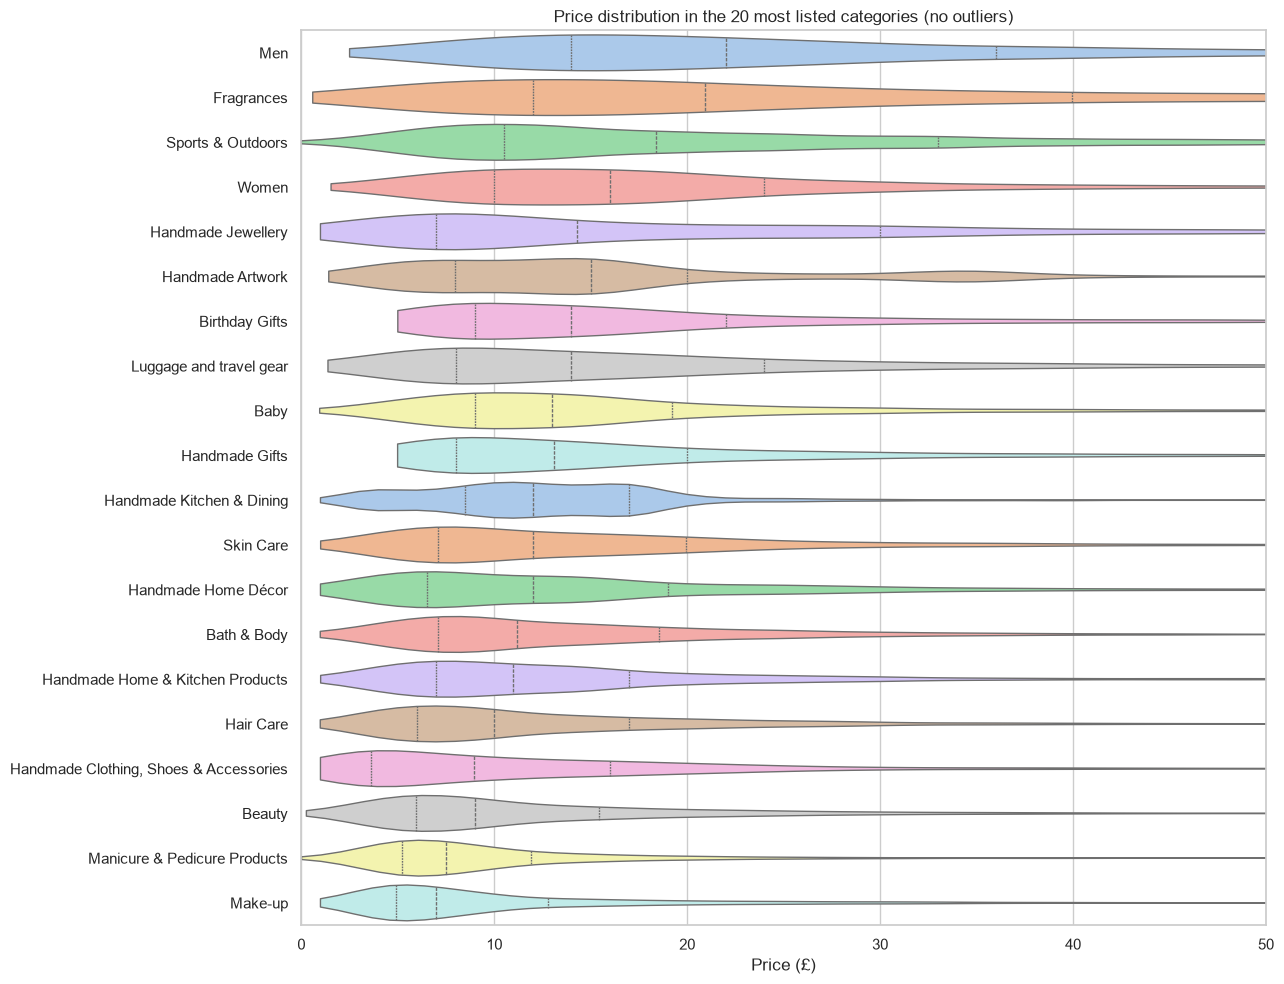

In [34]:
# Top 20 categories by number of listings
top20 = df_clean["category"].value_counts().head(20).index
violin_df = df_clean[df_clean["category"].isin(top20)]

# order the categories by median price, highest first, so the plot reads like a ranking
order = violin_df.groupby("category")["price"].median().sort_values(ascending=False).index

# Violin plots are slow with a lot of points: we draw a random sample of the filtered data
violin_data = violin_df.sample(200_000, random_state=42)

plt.figure(figsize=(13, 10))
sns.violinplot(data=violin_data, x="price", y="category", hue="category", order=order, hue_order=order,
               palette="pastel", legend=False, cut=0, inner="quartile", density_norm="width", linewidth=1)
plt.xlim(0, 50)   # display zoom: about 90% of these products cost up to £50
plt.title("Price distribution in the 20 most listed categories (no outliers)")
plt.xlabel("Price (£)")
plt.ylabel("")
plt.tight_layout()
plt.show()


In [35]:
# Median price of every category (no filter on the top categories); the count shows how reliable each median is
median_price = df_clean.groupby("category")["price"].agg(median="median", count="count")
median_price.sort_values("median", ascending=False).head(10)

,median,count
category,,
Desktop PCs,74.00,169
Boxing Shoes,69.79,3873
Tablets,69.00,4638
Graphics Cards,68.54,57
Motherboards,67.92,74
Made in Italy Handmade,64.00,1561
Digital Frames,63.90,310
Streaming Clients,62.68,1692
Golf Shoes,62.39,4493


### 2. Bar Charts
- Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
- Which product category commands the highest average price? Don't filter here by top categories.

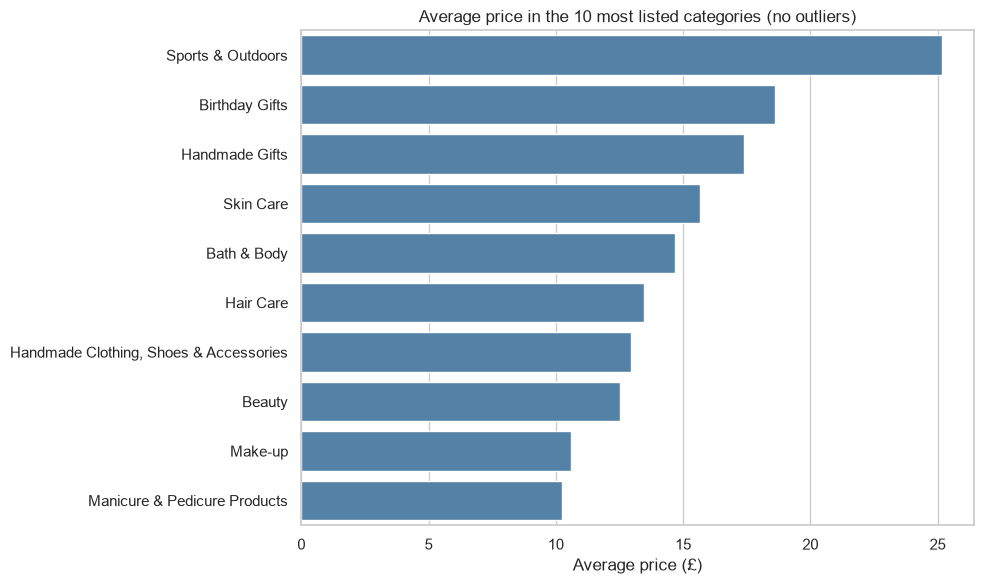

In [36]:
# Average price of the 10 most listed categories
top10 = df_clean["category"].value_counts().head(10).index
mean_price_top10 = df_clean[df_clean["category"].isin(top10)].groupby("category")["price"].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=mean_price_top10.values, y=mean_price_top10.index, color="steelblue")
plt.title("Average price in the 10 most listed categories (no outliers)")
plt.xlabel("Average price (£)")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [37]:
# Average price of every category (no filter on the top categories)
mean_price = df_clean.groupby("category")["price"].agg(mean="mean", count="count")
mean_price.sort_values("mean", ascending=False).head(10)

,mean,count
category,,
Motherboards,68.772432,74
Boxing Shoes,67.417803,3873
Desktop PCs,66.915562,169
Tablets,66.552971,4638
Graphics Cards,65.103509,57
Digital Frames,60.745129,310
Streaming Clients,60.241803,1692
Hockey Shoes,60.094796,221
Computer Cases,58.339884,173


### 3. Box Plots
- Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
- Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

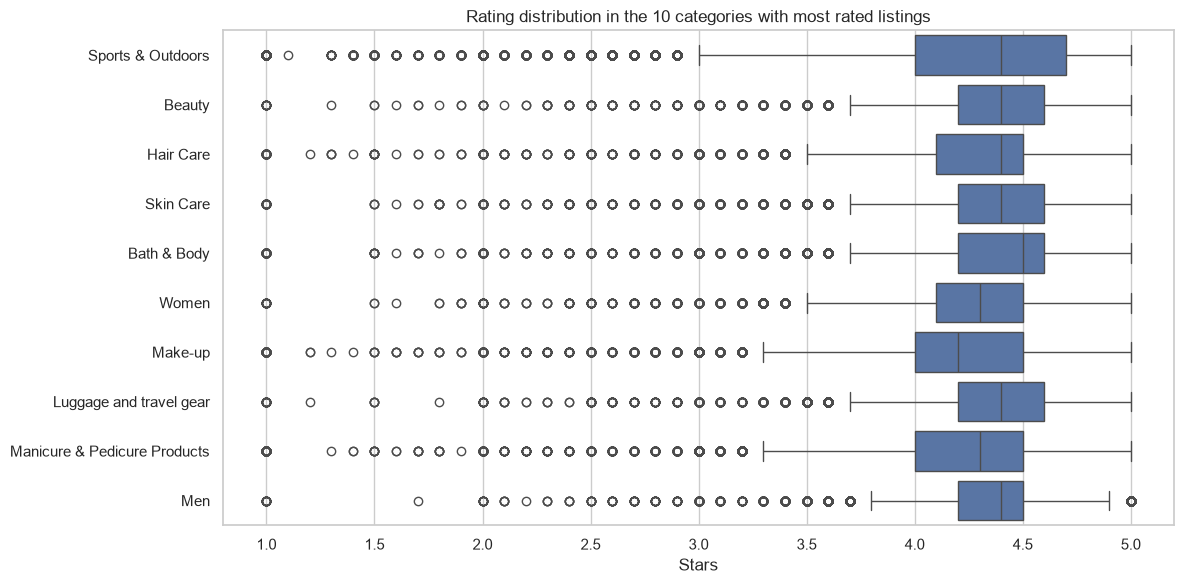

In [38]:
# Top 10 categories by number of rated listings
top10_rated = df_rated["category"].value_counts().head(10).index

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_rated[df_rated["category"].isin(top10_rated)], x="stars", y="category", order=top10_rated)
plt.title("Rating distribution in the 10 categories with most rated listings")
plt.xlabel("Stars")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [39]:
# Median rating of every category (no filter on the top categories); several categories can share the same median
median_rating = df_rated.groupby("category")["stars"].agg(median="median", count="count")
median_rating.sort_values(["median", "count"], ascending=False).head(10)

,median,count
category,,
Handmade Artwork,5.0,4155
Handmade Baby Products,5.0,1235
Made in Italy Handmade,5.0,303
"Handmade Clothing, Shoes & Accessories",4.9,4429
Handmade Kitchen & Dining,4.9,2739
Handmade Gifts,4.8,9871
Handmade Home Décor,4.8,7966
Birthday Gifts,4.8,7875
Handmade Home & Kitchen Products,4.7,10722


### Part 2 - Findings
- **Outlier removal**: with the IQR method (fences £-44.01 and £99.99) 327,688 listings (13.4%) were removed; 2,115,963 remain. Ratings are analysed only on products with `stars > 0` (47.3% of the remaining listings are unrated).
- **Prices by category (top 20 by listings)**: distributions are right-skewed and concentrated at low prices. Median prices go from about £7 (*Make-up*) to about £21 (*Men*), with *Fragrances* at £20 and *Sports & Outdoors* at £18.32.
- **Highest median price** across all categories: *Desktop PCs* (£74.00, 169 listings), followed by *Boxing Shoes* (£69.79) and *Tablets* (£69.00).
- **Highest average price** across all categories: *Motherboards* (£68.77, only 74 listings). Among the 10 most listed categories the average goes from £10.23 (*Manicure & Pedicure Products*) to £25.17 (*Sports & Outdoors*).
- **Ratings by category (top 10)**: medians are very similar, between 4.2 (*Make-up*) and 4.5 (*Bath & Body*).
- **Highest median rating** across all categories: 5.0, shared by *Handmade Artwork*, *Handmade Baby Products* and *Made in Italy Handmade*. These are handmade categories, so the ranking is a tie rather than a clear winner.
- **Caution**: the categories at the top of these rankings are small, so their averages are less reliable than those of large categories.


---
## Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: analyze how product ratings (`stars`) correlate with product prices.

### 1. Correlation Coefficients
- Calculate the correlation coefficient between `price` and `stars`.
- Is there a significant correlation between product price and its rating?

In [40]:
# Pearson (linear) and Spearman (monotonic, based on ranks) correlation between price and stars, rated products only
pearson = df_rated["price"].corr(df_rated["stars"])
spearman = df_rated["price"].corr(df_rated["stars"], method="spearman")
print(f"Pearson:  {pearson:.3f}")
print(f"Spearman: {spearman:.3f}")

# For comparison: what happens if the unrated products (stars = 0) are kept
print(f"Pearson including stars = 0: {df_clean['price'].corr(df_clean['stars']):.3f}")

Pearson:  0.007
Spearman: 0.025
Pearson including stars = 0: -0.078


### 2. Visualizations
- Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
- Use a correlation heatmap to visualize correlations between all numerical variables.
- Examine if product prices typically follow a normal distribution using a QQ plot.

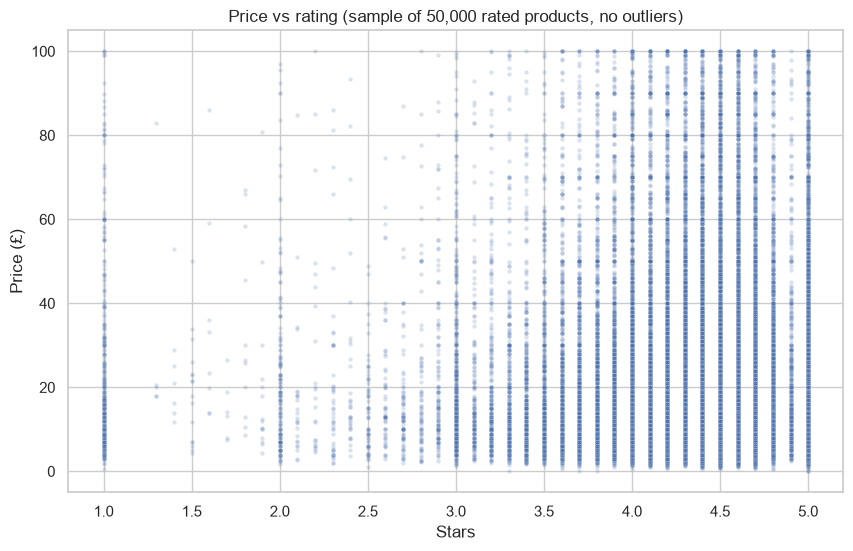

In [41]:
# Scatter plot on a random sample (more than 1 million points would be unreadable and slow)
scatter_data = df_rated.sample(50_000, random_state=42)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=scatter_data, x="stars", y="price", alpha=0.2, s=10)
plt.title("Price vs rating (sample of 50,000 rated products, no outliers)")
plt.xlabel("Stars")
plt.ylabel("Price (£)")
plt.show()

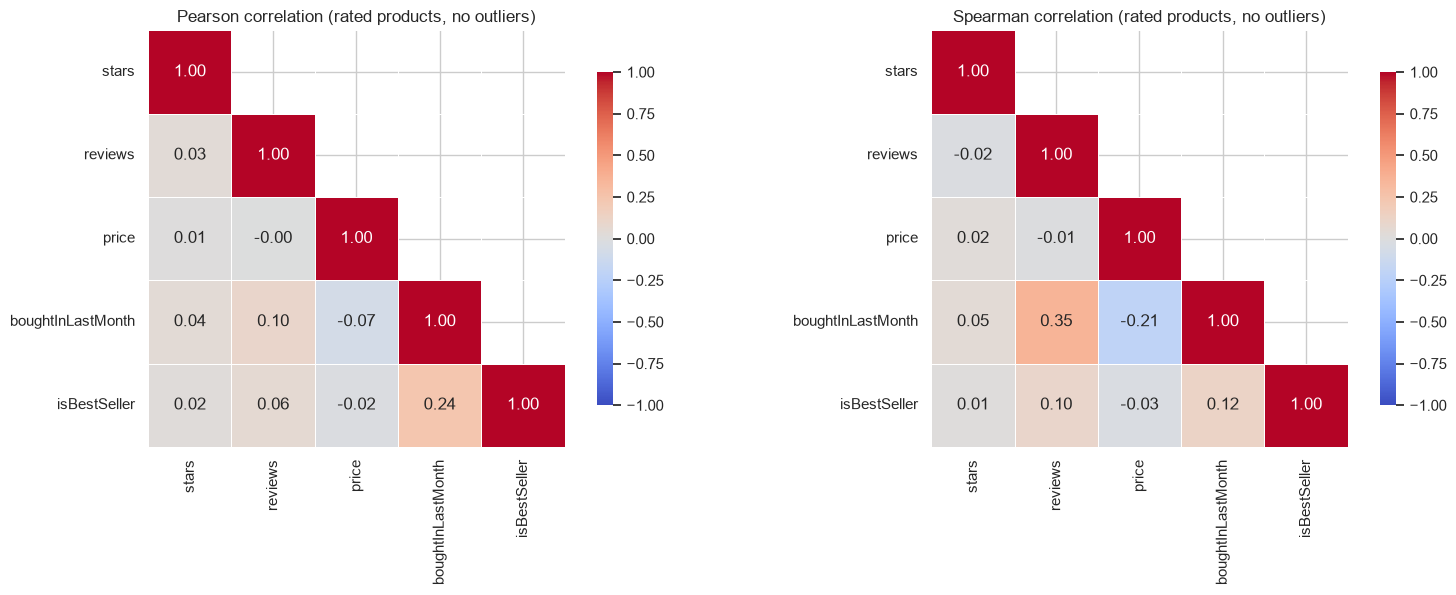

In [42]:
# Correlation heatmaps of the numerical variables (the identifier uid is not a measurement, so it is left out)
num_cols = ["stars", "reviews", "price", "boughtInLastMonth", "isBestSeller"]
num_data = df_rated[num_cols].astype(float)

# Mask the upper triangle: the matrix is symmetric, so it shows each pair only once
mask = np.triu(np.ones((len(num_cols), len(num_cols)), dtype=bool), k=1)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, method in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(num_data.corr(method=method), mask=mask, annot=True, fmt=".2f",
                cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True,
                linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
    ax.set_title(f"{method.capitalize()} correlation (rated products, no outliers)")
plt.tight_layout()
plt.show()


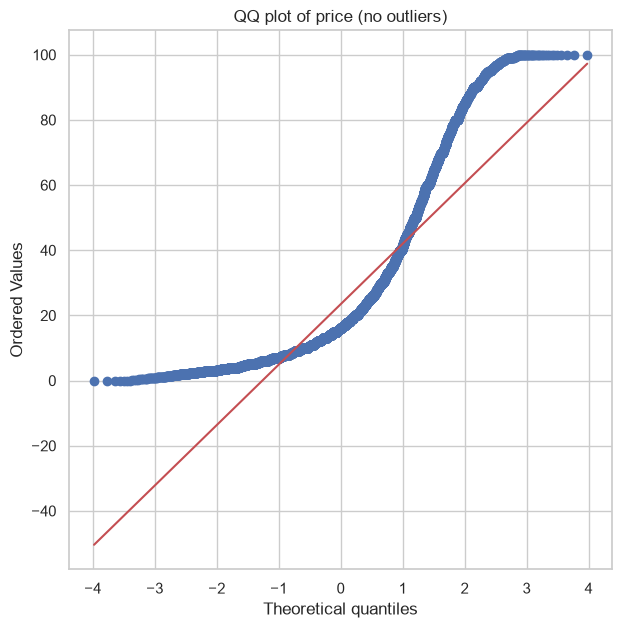

Skewness of price (no outliers): 1.64


In [43]:
# QQ plot of the price against a normal distribution (random sample to keep it fast)
price_sample = df_clean["price"].sample(20_000, random_state=42)

plt.figure(figsize=(7, 7))
stats.probplot(price_sample, dist="norm", plot=plt)
plt.title("QQ plot of price (no outliers)")
plt.show()

print(f"Skewness of price (no outliers): {df_clean['price'].skew():.2f}")

### Part 3 - Findings
- **Price and rating are essentially uncorrelated**: Pearson 0.007 and Spearman 0.025 on rated products. Including the unrated products (stars = 0) the Pearson becomes -0.078, a small negative value only due to the zeros.
- **Scatter plot**: products of every price get every rating; ratings do not increase with price.
- **Heatmap**: all correlations are weak. With Pearson the strongest is `boughtInLastMonth`–`isBestSeller` (0.24), but `reviews` and `boughtInLastMonth` are extremely skewed, so Pearson understates their links. With Spearman the strongest are `reviews`–`boughtInLastMonth` (0.35) and `price`–`boughtInLastMonth` (-0.21): products with more reviews sell more, and more expensive ones sell less. Price and stars stay at about 0.

- **QQ plot**: the points leave the line, so prices are not normal: the distribution is right-skewed (skewness 1.64 even without outliers).
- **Business reading**: a higher price does not signal a better-rated product, and customers do not rate expensive products more kindly.


---
## Bonus: the same analysis without removing the outliers

In [44]:
# Same questions on the full dataframe (outliers included): highest median / mean price and price-stars correlation
by_category = df.groupby("category")["price"].agg(median="median", mean="mean", count="count")
print("Highest median price:")
print(by_category.sort_values("median", ascending=False).head(5))
print("\nHighest average price:")
print(by_category.sort_values("mean", ascending=False).head(5))

df_rated_all = df[df["stars"] > 0]
print(f"\nPearson price-stars with outliers: {df_rated_all['price'].corr(df_rated_all['stars']):.3f}")
print(f"Spearman price-stars with outliers: {df_rated_all['price'].corr(df_rated_all['stars'], method='spearman'):.3f}")

Highest median price:
                             median         mean  count
category                                               
Laptops                    1042.725  1087.987827   7248
Desktop PCs                 810.400   926.816064   7395
Snowboards                  366.725   351.638812    640
Home Audio Record Players   326.080   529.665585   6374
3D Printers                 319.000  1018.036129    248

Highest average price:
                         median         mean  count
category                                           
Laptops                1042.725  1087.987827   7248
3D Printers             319.000  1018.036129    248
Desktop PCs             810.400   926.816064   7395
Home Office Furniture    96.970   622.135898   2462
Test & Measurement       94.770   559.382973    259

Pearson price-stars with outliers: -0.005
Spearman price-stars with outliers: 0.020


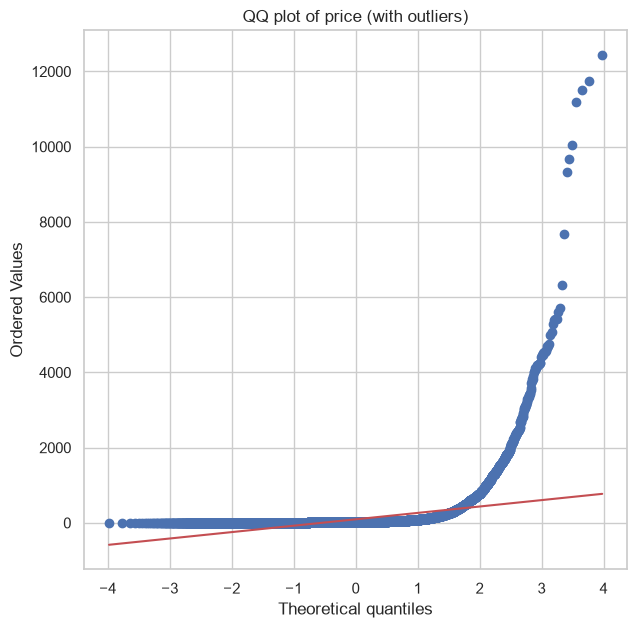

Skewness of price (with outliers): 27.49


In [45]:
# QQ plot and skewness of the price with outliers
plt.figure(figsize=(7, 7))
stats.probplot(df["price"].sample(20_000, random_state=42), dist="norm", plot=plt)
plt.title("QQ plot of price (with outliers)")
plt.show()

print(f"Skewness of price (with outliers): {df['price'].skew():.2f}")

### Bonus - Without removing the outliers
- **Rankings change a lot**: *Laptops* now have the highest median (£1,042.73) and the highest average price (£1,087.99), followed by *Desktop PCs* (median £810.40) and *3D Printers* (average £1,018.04). Laptops were invisible before because their normal prices are above the £99.99 fence.
- **Correlation**: price and stars stay uncorrelated (Pearson -0.005, Spearman 0.020).
- **Distribution**: the skewness of the price rises from 1.64 to 27.49 and the QQ plot is much further from the line.
- **Insight**: the IQR rule applied to the whole dataset treats expensive categories as outliers even when their prices are legitimate. For comparing categories it is better to keep the outliers or to remove them within each category.
